# Names:

**- Fay Alzahrany (44510217)**

**- Linda Almajnooni (446002770)**


# Introduction

In this project, we built a Machine Learning model to classify different types of Saudi dates using image data from the SODA Challenge dataset.

The project includes:
- Data exploration
- Image preprocessing
- Model training
- Model evaluation

The main goal is to predict the correct class label for each date image.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import os

from sklearn.model_selection import train_test_split

In [2]:
train_df = pd.read_csv('/kaggle/input/competitions/soda-challenge/soda_dataset/train.csv')
test_df = pd.read_csv('/kaggle/input/competitions/soda-challenge/soda_dataset/test.csv')

print("Training Data Shape:", train_df.shape)

train_df.head()

Training Data Shape: (1829, 2)


,id,label
0,1,13
1,2,1
2,3,11
3,4,11
4,5,2


In [3]:
print(train_df['label'].value_counts())

label
13    141
1     141
11    141
2     141
9     141
7     141
4     141
5     141
3     141
10    140
8     140
6     140
12    140
Name: count, dtype: int64


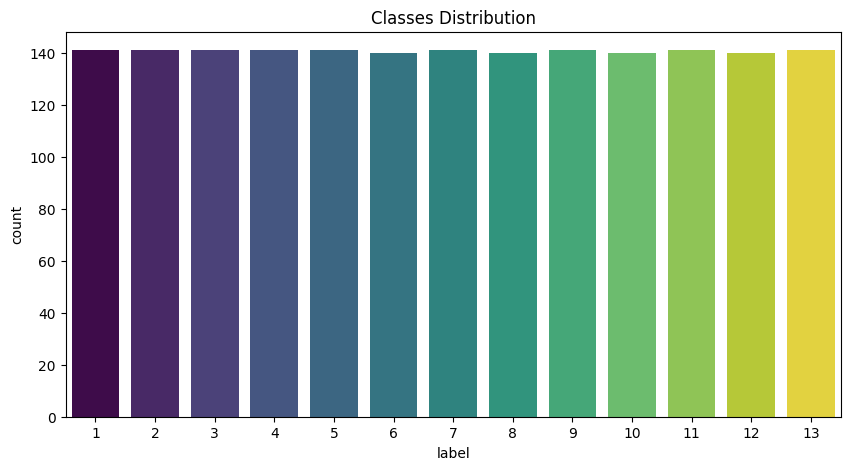

In [4]:
plt.figure(figsize=(10,5))

sns.countplot(data=train_df, x='label', hue='label', palette='viridis', legend=False)

plt.title('Classes Distribution')

plt.show()

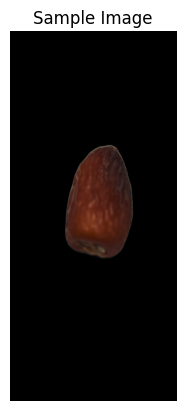

In [5]:
sample_path = "/kaggle/input/competitions/soda-challenge/soda_dataset/images/train/1.png"

img = cv2.imread(sample_path)

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img)

plt.title("Sample Image")

plt.axis('off')

plt.show()

In [6]:
print(train_df.isnull().sum())

id       0
label    0
dtype: int64


In [7]:
broken_images = []

for image_id in train_df['id']:

    jpg_path = f"/kaggle/input/competitions/soda-challenge/soda_dataset/images/train/{image_id}.jpg"

    png_path = f"/kaggle/input/competitions/soda-challenge/soda_dataset/images/train/{image_id}.png"

    if os.path.exists(jpg_path):
        path = jpg_path

    elif os.path.exists(png_path):
        path = png_path

    else:
        broken_images.append(image_id)

print("Broken Images:", broken_images)

Broken Images: []


In [8]:
images = []
labels = []

for index, row in train_df.iterrows():

    jpg_path = f"/kaggle/input/competitions/soda-challenge/soda_dataset/images/train/{row['id']}.jpg"

    png_path = f"/kaggle/input/competitions/soda-challenge/soda_dataset/images/train/{row['id']}.png"

    if os.path.exists(jpg_path):
        path = jpg_path

    else:
        path = png_path

    img = cv2.imread(path)

    img = cv2.resize(img, (64,64))

    img = img / 255.0

    images.append(img.flatten())

    labels.append(row['label'])

X = np.array(images)

y = np.array(labels)

print("Training Data Dimensions:", X.shape)

print("Labels Dimensions:", y.shape)

Training Data Dimensions: (1829, 12288)
Labels Dimensions: (1829,)


In [9]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Set Shape:", X_train.shape)

print("Validation Set Shape:", X_val.shape)

Training Set Shape: (1463, 12288)
Validation Set Shape: (366, 12288)


In [10]:
print("Data preprocessing completed successfully.")

Data preprocessing completed successfully.


In [11]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Set Shape:", X_train.shape)

print("Validation Set Shape:", X_val.shape)

Training Set Shape: (1463, 12288)
Validation Set Shape: (366, 12288)


In [12]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=3)

model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


In [13]:
y_pred = model.predict(X_val)

In [14]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_val, y_pred)

print("Model Accuracy:", accuracy)

Model Accuracy: 0.319672131147541


In [15]:
from sklearn.metrics import classification_report

print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           1       0.32      0.68      0.44        28
           2       0.25      0.50      0.33        28
           3       0.22      0.29      0.25        28
           4       0.28      0.50      0.36        28
           5       0.32      0.34      0.33        29
           6       0.45      0.54      0.49        28
           7       0.27      0.25      0.26        28
           8       0.36      0.14      0.21        28
           9       0.46      0.21      0.29        28
          10       0.23      0.11      0.15        28
          11       0.50      0.21      0.29        29
          12       0.45      0.18      0.26        28
          13       0.46      0.21      0.29        28

    accuracy                           0.32       366
   macro avg       0.35      0.32      0.30       366
weighted avg       0.35      0.32      0.30       366



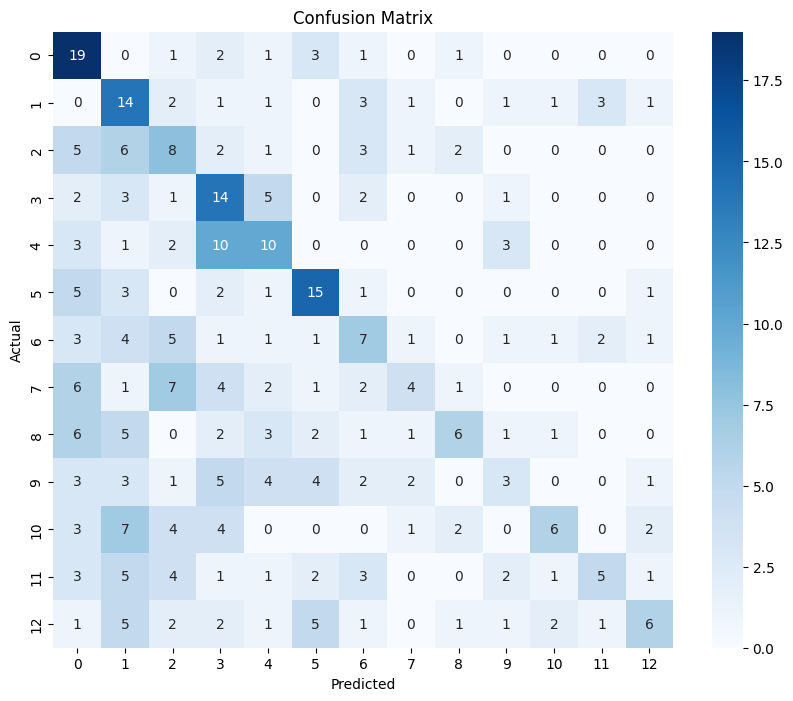

In [16]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(10,8))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [17]:
test_images = []

for image_id in test_df['id']:

    jpg_path = f"/kaggle/input/competitions/soda-challenge/soda_dataset/images/test/{image_id}.jpg"

    png_path = f"/kaggle/input/competitions/soda-challenge/soda_dataset/images/test/{image_id}.png"

    if os.path.exists(jpg_path):
        path = jpg_path

    else:
        path = png_path

    img = cv2.imread(path)

    img = cv2.resize(img, (64,64))

    img = img / 255.0

    test_images.append(img.flatten())

X_test = np.array(test_images)

print("Test Data Shape:", X_test.shape)

Test Data Shape: (784, 12288)


In [18]:
test_predictions = model.predict(X_test)

In [19]:
submission = pd.DataFrame({
    'id': test_df['id'],
    'label': test_predictions
})

submission.to_csv('submission.csv', index=False)

print("submission.csv created successfully.")

submission.csv created successfully.
